<a href="https://colab.research.google.com/github/LuckyMayHedgehog/Machine-Learning-data-science/blob/main/03_regularized_regression/ML_lab3_california_housing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score

housing = fetch_california_housing(as_frame=True)

X = housing.data
y = housing.target

print("Розмірність матриці ознак X:", X.shape)
print("Назви ознак:\n", list(X.columns))
print("\nПерші 5 рядків ознак:")
print(X.head())

Розмірність матриці ознак X: (20640, 8)
Назви ознак:
 ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Перші 5 рядків ознак:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  


| Параметр   | Що означає                        |
| ---------- | --------------------------------- |
| MedInc     | середній дохід населення району   |
| HouseAge   | середній вік будинків             |
| AveRooms   | середня кількість кімнат          |
| AveBedrms  | середня кількість спалень         |
| Population | населення району                  |
| AveOccup   | середня кількість людей у будинку |
| Latitude   | широта                            |
| Longitude  | довгота                           |

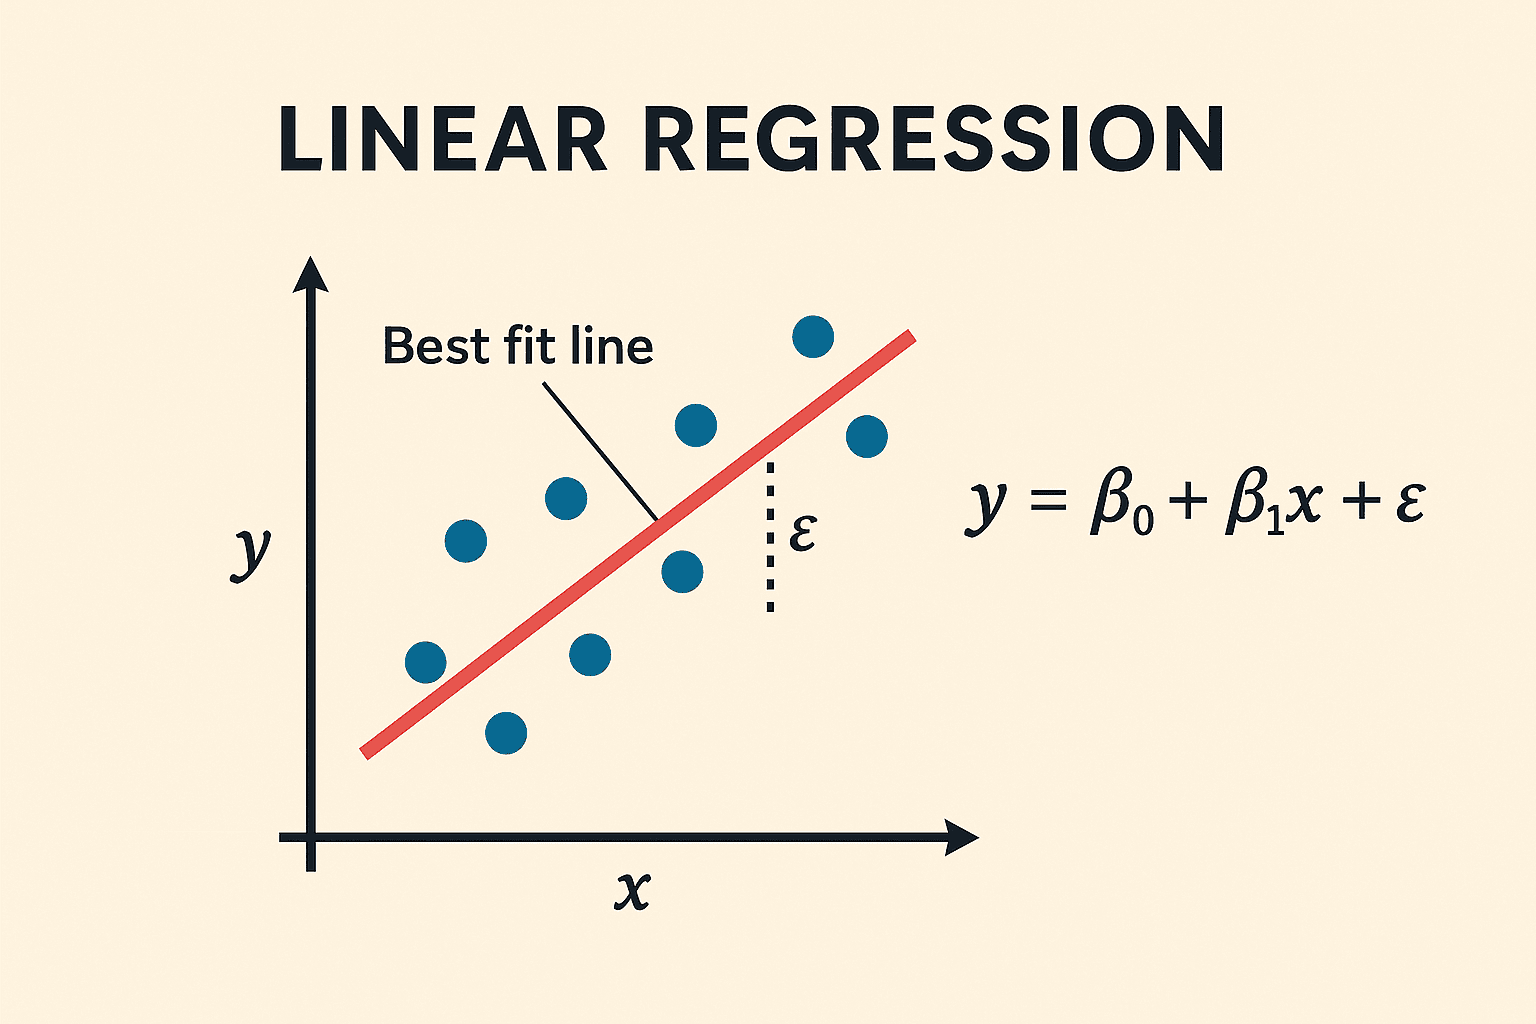

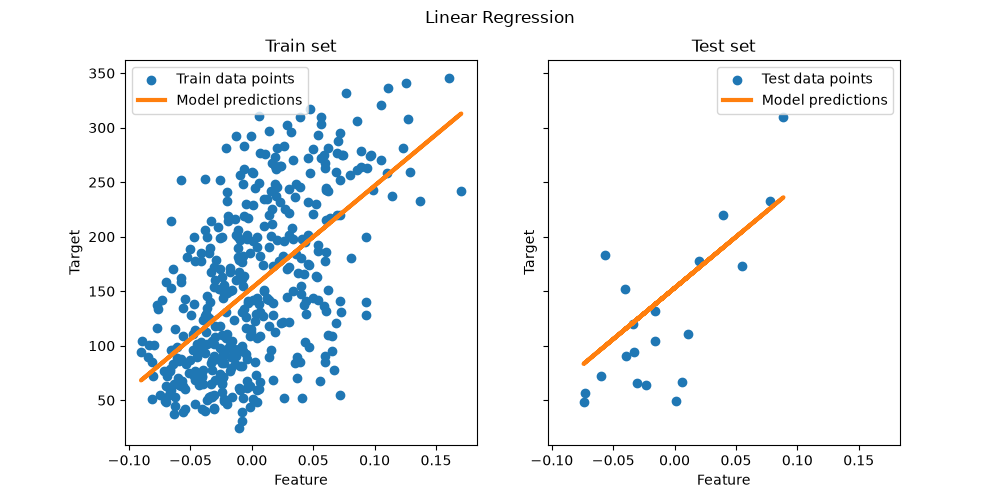

#Лінійна регресія - це метод машинного навчання, який використовується для того, щоб передбачити числове значення на основі інших даних.  

знаємо характеристики району Каліфорнії -> хочемо передбачити середню ціну житла.  

вхідні дані -> математична залежність -> прогноз числового значення

Як модель розуміє, яка пряма краща?

Для цього існує функція втрат.

У класичній лінійній регресії дуже часто використовується MSE - Mean Squared Error.

беремо реальне значення;

 віднімаємо прогноз;

 підносимо помилку до квадрата;

 робимо це для всіх об'єктів;

 знаходимо середнє.



Чому квадрат? Щоб не було втрат даних: Припустимо, модель помилилася +5. А іншим разом -5 = 5+(-5) = 0, ніби помилки немає.  





Множинна лінійна регресія - у нас багато ознак.





#**RIDGE** -

цільова змінна - середня ціна житла.  

Ми хочемо: за 8 характеристиками району передбачити його середню ціну.

Модель звичайної лінійної регресії знайшла коефіцієнти. з'являється проблема: лінійна регресія через особливості даних вирішила: треба поставити величезний коефіцієнт для MedInc!

Тобто коефіцієнти стали дуже великими.  звичайні least squares можуть бути нестабільними, коли ознаки пов'язані між собою - це називається multicollinearity. У такій ситуації оцінки коефіцієнтів можуть мати велику варіативність  



#Ridge: я хочу точні прогнози. Але я також не хочу, щоб коефіцієнти ставали величезними. Ridge додає до звичайної помилки додатковий штраф.  Зменшуй занадто великі коефіцієнти  

shrinkage - стискання коефіцієнтів. І там прямо зазначено: чим більший alpha, тим сильніше це стискання.



Overfitting, Захист: Ridge трохи стримує модель - Не підлаштовуйся настільки сильно. Не роби коефіцієнти величезними. У результаті модель може трохи гірше описувати train, зате краще узагальнювати на нові дані.

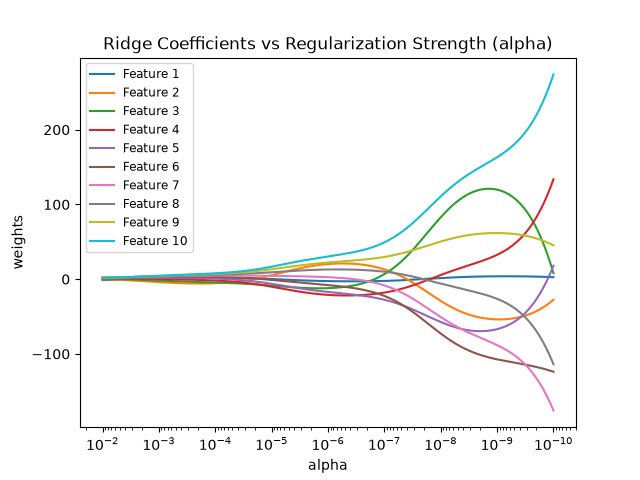

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=13
)

# 2. Стандартизація ознак (z-score: нульове середнє, одинична дисперсія)
scaler = StandardScaler()
# рахуємо параметри стандартизації ТІЛЬКИ на тренувальній вибірці
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Створення та навчання Ridge-регресії
# Параметр alpha відповідає за силу регуляризації (за замовчуванням alpha=1.0)
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)

# 4. Прогнозування цін для тестової вибірки
y_pred_ridge = ridge_model.predict(X_test_scaled)

# 5. Оцінка якості моделі
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

print("Результати Ridge-регресії")
print(f"RMSE: {rmse_ridge:.4f}")
print(f"R² (коефіцієнт детермінації): {r2_ridge:.4f}\n")

# 6. Коефіцієнти моделі для кожної ознаки
ridge_coefs = pd.Series(ridge_model.coef_, index=X.columns)
print("Отримані ваги (коефіцієнти w_i):")
print(ridge_coefs.round(4).to_string())
print(f"\nВільний член (intercept, w_0): {ridge_model.intercept_:.4f}")

Результати Ridge-регресії
RMSE: 0.7299
R² (коефіцієнт детермінації): 0.6047

Отримані ваги (коефіцієнти w_i):
MedInc        0.8249
HouseAge      0.1218
AveRooms     -0.2732
AveBedrms     0.3170
Population   -0.0068
AveOccup     -0.0394
Latitude     -0.9050
Longitude    -0.8683

Вільний член (intercept, w_0): 2.0674


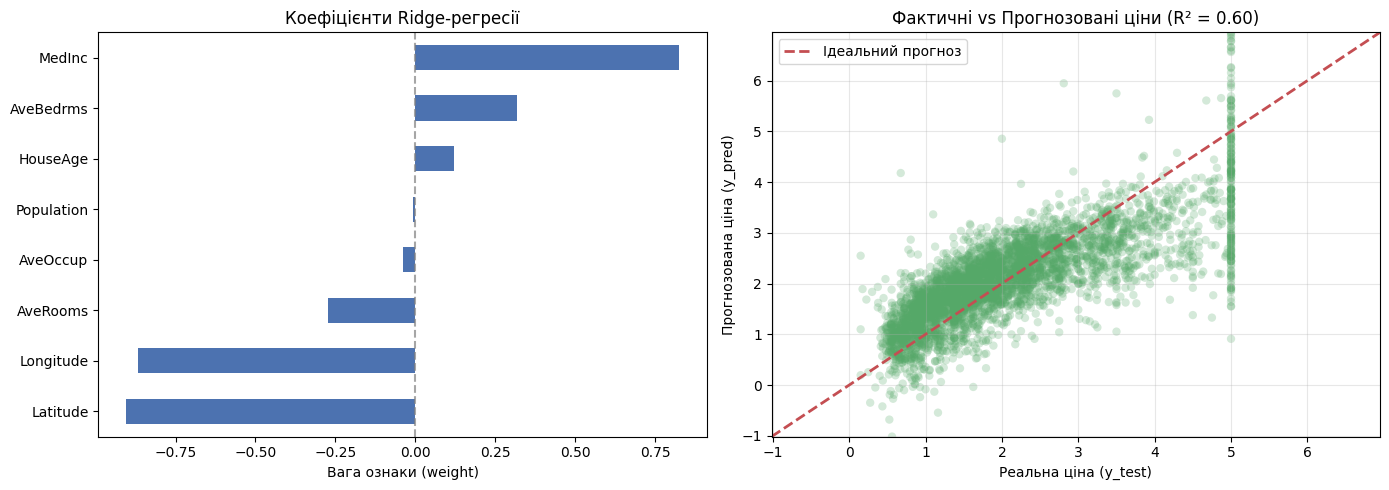

In [ ]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Ваги ознак (які змінні роблять найбільший внесок)
ridge_coefs.sort_values().plot(kind="barh", ax=ax1, color="#4C72B0")
ax1.axvline(x=0, color="grey", linestyle="--", alpha=0.7)
ax1.set_title("Коефіцієнти Ridge-регресії")
ax1.set_xlabel("Вага ознаки (weight)")

# 2. Фактичні значення проти передбачених
ax2.scatter(y_test, y_pred_ridge, alpha=0.25, color="#55A868", edgecolors="none")
# Лінія ідеального прогнозу
lims = [
    min(y_test.min(), y_pred_ridge.min()),
    max(y_test.max(), y_pred_ridge.max()),
]
ax2.plot(lims, lims, color="#C44E52", linestyle="--", linewidth=2, label="Ідеальний прогноз")
ax2.set_xlim(lims)
ax2.set_ylim(lims)
ax2.set_title(f"Фактичні vs Прогнозовані ціни (R² = {r2_ridge:.2f})")
ax2.set_xlabel("Реальна ціна (y_test)")
ax2.set_ylabel("Прогнозована ціна (y_pred)")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Вертикальна лінія на позначці $y = 5.0$: яскраво виражений вертикальний стовпчик точок з'явився через особливість самого датасету California Housing - ціни, що перевищували $500{,}000$, були штучно обмежені (censored/capped) верхньою планкою $5.0$. Лінійна модель не знає про це обмеження і передбачає як вищі, так і нижчі значення.

Вихідна ситуація: ми дали моделі 8 ознак району (дохід, кімнати, координати тощо) і хотіли передбачити ціну житла.

Пастка звичайної лінійної регресії (OLS): ознаки сильно корелюють між собою (мультиколінеарність) - наприклад, Latitude та Longitude разом визначають конкретну точку на карті, а AveRooms пов'язана з AveBedrms. Без контролю звичайна регресія починає розгойдувати ваги до гігантських значень зі знаками плюс і мінус, аби загнати тренувальну помилку в нуль (перенавчання).

стримавши ваги, модель не перенавчилася під тренувальні шуми і впевнено тримає хмару точок навколо червоної лінії «ідеального прогнозу» на нових тестових даних.
Ridge навмисно збільшує зсув (bias), аби знизити розкид (variance). Через це вона не намагається «вигинатися» під нелінійні патерни - хмара точок помітно розмита.
Модель спокійно видає прогнози вище 5.0 (аж до 6.0+) для найдорожчих будинків, оскільки це чиста пряма, яка штрафує великі коефіцієнти, але не знає про штучне «зрізання» цін датасету на позначці 5.0.

========================================================================

Lasso - теж лінійна регресія, але з іншим способом регуляризації.

Звичайна лінійна регресія:

MedInc       → w₁ HouseAge     → w₂ AveRooms     → w₃   ...

і використовує їх для прогнозу ціни.  



Ridge - Я хочу маленьку помилку, але ще хочу, щоб коефіцієнти не були надто великими  

Lasso - А навіщо мені взагалі залишати всі ознаки?  

НАПРИКЛАД:

AveBedrms   -1.9 Population   0.02 AveOccup    -0.01 Latitude    -0.8  

Population майже нічого не додає → зробимо коефіцієнт 0  

AveOccup майже нічого не додає → зробимо коефіцієнт 0  



Lasso не видаляє сам стовпчик із DataFrame.



Воно робить його коефіцієнт рівним нулю

Lasso моделлю зі sparse coefficients — розрідженими коефіцієнтами. Вона може встановлювати коефіцієнти точно в 0 і тому може використовуватися для відбору ознак



Чи варто мені залишати цей маленький коефіцієнт, якщо за нього я отримую штраф?  Ні. Просто поставлю його в 0  

Ознака фактично перестає впливати на модель.  

In [ ]:
# 1. Створення та навчання Lasso-регресії
# Використовуємо ті самі стандартизовані дані X_train_scaled та y_train
lasso_model = Lasso(alpha=0.01, random_state=13)
lasso_model.fit(X_train_scaled, y_train)

# 2. Прогнозування цін на тестовій вибірці
y_pred_lasso = lasso_model.predict(X_test_scaled)

# 3. Оцінка якості моделі
mse_lasso = mean_squared_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mse_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)

print("Результати Lasso-регресії (alpha=0.01)")
print(f"RMSE: {rmse_lasso:.4f}")
print(f"R² (коефіцієнт детермінації): {r2_lasso:.4f}\n")

# 4. Аналіз отриманих коефіцієнтів
lasso_coefs = pd.Series(lasso_model.coef_, index=X.columns)
print("Отримані ваги (коефіцієнти w_i):")
print(lasso_coefs.round(4).to_string())

# Рахуємо, скільки ознак занулено
zero_features = lasso_coefs[np.isclose(lasso_coefs, 0.0)].index.tolist()
print(f"\nКількість занулених ознак: {len(zero_features)} з {len(X.columns)}")
if zero_features:
    print(f"Повністю виключені ознаки: {', '.join(zero_features)}")
print(f"Вільний член (intercept, w_0): {lasso_model.intercept_:.4f}")

Результати Lasso-регресії (alpha=0.01)
RMSE: 0.7338
R² (коефіцієнт детермінації): 0.6004

Отримані ваги (коефіцієнти w_i):
MedInc        0.7717
HouseAge      0.1291
AveRooms     -0.1287
AveBedrms     0.1724
Population   -0.0000
AveOccup     -0.0295
Latitude     -0.8014
Longitude    -0.7573

Кількість занулених ознак: 1 з 8
Повністю виключені ознаки: Population
Вільний член (intercept, w_0): 2.0674


================================================

Еластична мережа - лінійна регресія, яка одночасно використовує L1-регуляризацію (як Lasso) та L2-регуляризацію (як Ridge)

давайте використаємо і Ridge, і Lasso одночасно

l1_ratio - скільки в нашій моделі буде Lasso, а скільки Ridge.  



| Модель                | Регуляризація | Що робить                                   |
| --------------------- | ------------- | ------------------------------------------- |
| **Linear Regression** | Немає         | Просто мінімізує помилку                    |
| **Ridge**             | L2            | Зменшує великі коефіцієнти                  |
| **Lasso**             | L1            | Може зробити коефіцієнти `0`                |
| **Elastic Net**       | L1 + L2       | І зменшує коефіцієнти, і може робити їх `0` |


In [ ]:
# 1. Створення та навчання моделі ElasticNet
# alpha=0.01 забезпечує помірний штраф, l1_ratio=0.5 дає однаковий вплив L1 та L2
elastic_model = ElasticNet(alpha=0.01, l1_ratio=0.5, random_state=42)
elastic_model.fit(X_train_scaled, y_train)

# 2. Прогнозування на тестовій вибірці
y_pred_elastic = elastic_model.predict(X_test_scaled)

# 3. Розрахунок метрик якості
mse_elastic = mean_squared_error(y_test, y_pred_elastic)
rmse_elastic = np.sqrt(mse_elastic)
r2_elastic = r2_score(y_test, y_pred_elastic)

print("Результати ElasticNet (alpha=0.01, l1_ratio=0.5)")
print(f"RMSE: {rmse_elastic:.4f}")
print(f"R² (коефіцієнт детермінації): {r2_elastic:.4f}\n")

# 4. Аналіз отриманих ваг
elastic_coefs = pd.Series(elastic_model.coef_, index=X.columns)
print("Отримані ваги (коефіцієнти w_i):")
print(elastic_coefs.round(4).to_string())

# Кількість занулених ознак
zero_features_elastic = elastic_coefs[np.isclose(elastic_coefs, 0.0, atol=1e-4)].index.tolist()
print(f"\nКількість занулених ознак: {len(zero_features_elastic)} з {len(X.columns)}")
if zero_features_elastic:
    print(f"Повністю вилучені ознаки: {', '.join(zero_features_elastic)}")
print(f"Вільний член (intercept, w_0): {elastic_model.intercept_:.4f}")

Результати ElasticNet (alpha=0.01, l1_ratio=0.5)
RMSE: 0.7322
R² (коефіцієнт детермінації): 0.6022

Отримані ваги (коефіцієнти w_i):
MedInc        0.7963
HouseAge      0.1316
AveRooms     -0.1906
AveBedrms     0.2305
Population   -0.0000
AveOccup     -0.0349
Latitude     -0.7966
Longitude    -0.7559

Кількість занулених ознак: 1 з 8
Повністю вилучені ознаки: Population
Вільний член (intercept, w_0): 2.0674


#Порівняти отримані результати. Яка модель точніше наближає дані? У яких випадках буде точніше гребнева, Lasso регресії або Еластична мережа?



Найточніше тестові дані наближає Ridge-регресія (вона має найменшу помилку $\text{RMSE} = 0.7299$ та найвищий коефіцієнт детермінації $R^2 = 0.6047$).Різниця між усіма трьома моделями невелика

Різниця між усіма трьома моделями невелика ($R^2 \approx 0.60$), проте перевага Ridge тут закономірна: майже всі наявні ознаки (зокрема дохід, координати та характеристики житла) роблять ненульовий внесок у ціну, а між змінними присутня помітна кореляція (наприклад, Latitude з Longitude або AveRooms з AveBedrms). Ridge зберегла всі змінні в грі, розподіливши ваги між пов'язаними ознаками без їх різкого виключення. Lasso та ElasticNet занулили ознаку Population, отримавши трохи нижчу якість наближення

#У яких випадках буде точніше гребнева, Lasso регресії або Еластична мережа?

Гребнева регресія (Ridge, $L_2$):Коли між багатьма ознаками є сильна кореляція (мультиколінеарність).Коли більшість або всі ознаки в датасеті є дійсно інформативними і важливими для прогнозу.Коли кількість спостережень суттєво перевищує кількість ознак ($n > p$) і немає потреби позбуватися ознак для інтерпретованості.

Lasso-регресія ($L_1$):Коли в датасеті є велика кількість шумних або непотрібних ознак (розріджені дані, sparse signals).Коли ознак дуже багато, можливо навіть більше, ніж спостережень ($p > n$), і критично необхідно провести автоматичний відбір ознак (feature selection).Коли потрібна проста, компактна модель, яку легко інтерпретувати бізнесу (Lasso просто обнуляє коефіцієнти перед неважливими факторами).

Еластична мережа (ElasticNet, L
1
​
 +L
2
​
 ):

Коли одночасно є і мультиколінеарність (групи корельованих ознак), і велика кількість шуму. Lasso зазвичай випадково обирає одну ознаку з корельованої групи і занулює решту, що робить її нестабільною; ElasticNet завдяки компоненту L
2
​
  зберігає груповий ефект, а завдяки L
1
​
  відсікає суто некорисні змінні.
